# Workshop 3-1: Linear regression

**Real-life problem:** What should this home be worth, given what we know about its neighbourhood?

**My twist:** Replace the synthetic `Y = mX + c` with real data: `sklearn.datasets.fetch_california_housing` (downloads on first run). Fit median house value from median income, then add a second feature and compare.

**Done when:** R² and MAE for the one-feature vs two-feature model, a residual plot, and a note on where the model is wrong (the dataset caps values at $500k).

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: how linear regression works (the lecturer's baseline)

100 made-up points on the line `Y = 0.3X + 2` plus noise, then a fit with scikit-learn. (One fix: the final print cell used `% regr.coef_`, which NumPy 2 rejects, so it now indexes `[0][0]`.)

In [11]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

In [12]:
np.random.seed(0)
X = 2 * np.random.randn(100) + 1.5     # Array of 100 values with mean = 1.5, stddev = 2
noise = 0.5 * np.random.randn(100)     # Generate 100 noise terms
Y = 0.3*X + 2 + noise                  # Actual values of Y = mX + c + noise

In [13]:
df = pd.DataFrame(
    {'X': X,
     'Y': Y}
)
# Show the first five rows of our dataframe
df.head()

,X,Y
0,5.028105,4.450007
1,2.300314,2.016215
2,3.457476,2.402000
3,5.981786,4.279234
4,5.235116,2.983973


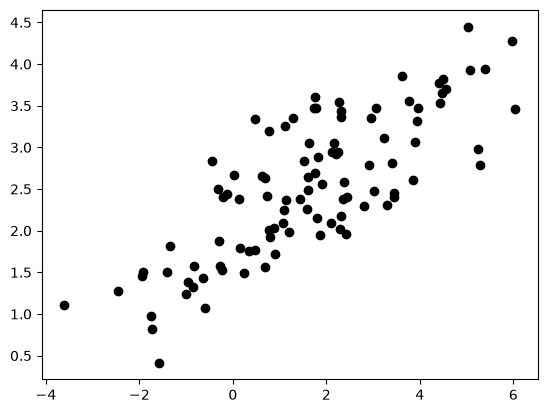

In [14]:
plt.scatter(df['X'], df['Y'], color='black')

In [15]:
( x , y ) = ( df.iloc[:,:-1] , df.iloc[:,-1:] )

In [16]:
regr = linear_model.LinearRegression()

In [17]:
regr.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.33]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['X']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[1.99]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [18]:
y_pred = regr.predict(x)

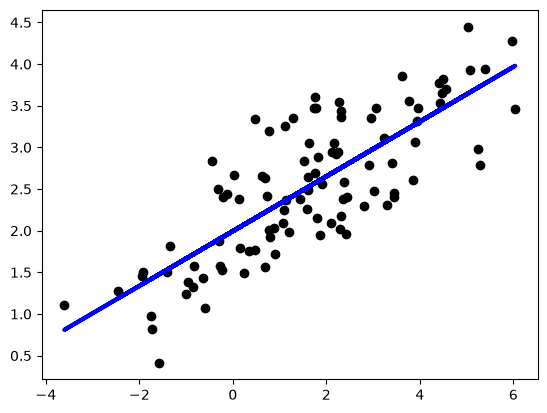

In [19]:
plt.scatter(x, y,  color='black')
plt.plot(x, y_pred, color='blue', linewidth=3)

In [20]:
print('Mean squared error: %.2f' % mean_squared_error(y, y_pred))
print('Regression coefficients: %.2f' % regr.coef_[0][0])
print('Intercept: %.2f' % regr.intercept_[0])
print('R2 score: %.2f' % r2_score(y, y_pred))

Mean squared error: 0.26
Regression coefficients: 0.33
Intercept: 1.99
R2 score: 0.62


---
## Part B: real life: what should this home be worth?

**Problem:** can a simple, explainable model estimate the median house value of a neighbourhood from a few facts about it?

**Data:** scikit-learn's California housing set: 20,640 census *block groups* (small neighbourhoods) from the **1990** census. `MedInc` is median income in units of **$10,000**; the target is median house value, which I convert to **dollars (1990 dollars)**. This is a modelling exercise, not a valuation tool: 1990 prices are not today's, and these are neighbourhood medians, not individual homes.

**Plan:** one feature (income) → add a second → see what the full feature set can do → look at where the model goes wrong.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_absolute_error

housing = fetch_california_housing(as_frame=True)          # downloads once, then cached on your computer
df = housing.frame
features = list(housing.feature_names)
X, y = df[features], df['MedHouseVal'] * 100_000           # target in dollars

CAP = 500_000
print(f'{len(df):,} neighbourhoods | median house value: ${y.median():,.0f} | cheapest ${y.min():,.0f}, dearest ${y.max():,.0f}')
print(f'{(y >= CAP).sum()} neighbourhoods ({(y >= CAP).mean() * 100:.1f}%) are capped at ${CAP:,}: the dataset cannot show anything higher')

# hold 20% back; every score below is on neighbourhoods the model never saw
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
capped_test = (y_test >= CAP).to_numpy()

20,640 neighbourhoods | median house value: $179,700 | cheapest $14,999, dearest $500,001
992 neighbourhoods (4.8%) are capped at $500,000: the dataset cannot show anything higher


### 1. One feature: income

each extra $10,000 of median income adds about $42,032 to the predicted house value
(a neighbourhood with zero income would be predicted at $44,321: the line is only meaningful over the observed income range)


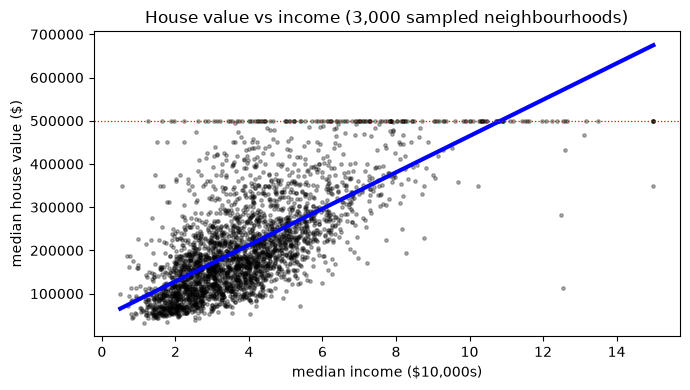

In [22]:
one = LinearRegression().fit(X_train[['MedInc']], y_train)
print(f'each extra $10,000 of median income adds about ${one.coef_[0]:,.0f} to the predicted house value')
print(f'(a neighbourhood with zero income would be predicted at ${one.intercept_:,.0f}: the line is only meaningful over the observed income range)')

sample = X_train.sample(3000, random_state=0)
plt.figure(figsize=(7, 4))
plt.scatter(sample['MedInc'], y_train[sample.index], s=6, alpha=0.3, color='black')
xs = np.linspace(0.5, 15, 50)
plt.plot(xs, one.intercept_ + one.coef_[0] * xs, color='blue', linewidth=3)
plt.axhline(CAP, color='r', ls=':', lw=0.9)
plt.xlabel('median income ($10,000s)'); plt.ylabel('median house value ($)')
plt.title('House value vs income (3,000 sampled neighbourhoods)')
plt.tight_layout(); plt.show()

### 2. Which second feature helps most?
Add each other feature to income, one at a time, and measure with 5-fold cross-validation on the **training** data only (so the test set stays untouched for the final comparison).

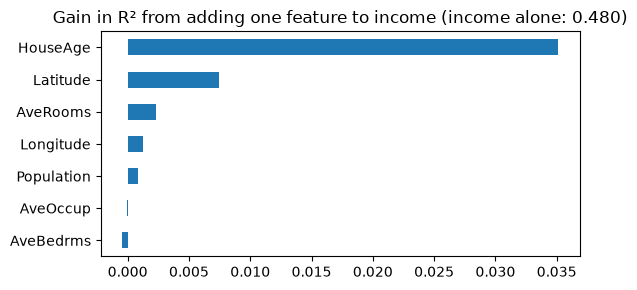

best second feature: HouseAge


In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)
alone = cross_val_score(LinearRegression(), X_train[['MedInc']], y_train, cv=cv, scoring='r2').mean()
gain = {f: cross_val_score(LinearRegression(), X_train[['MedInc', f]], y_train, cv=cv, scoring='r2').mean() - alone
        for f in features if f != 'MedInc'}
gain = pd.Series(gain).sort_values()
second = gain.idxmax()

gain.plot(kind='barh', figsize=(6, 3), title=f'Gain in R² from adding one feature to income (income alone: {alone:.3f})')
plt.tight_layout(); plt.show()
print('best second feature:', second)

### 3. The comparison (on held-out neighbourhoods)

In [24]:
def evaluate(cols):
    model = LinearRegression().fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])
    return model, pred, {'R²': r2_score(y_test, pred),
                         'typical error, MAE ($)': mean_absolute_error(y_test, pred),
                         'MAE excl. capped ($)': mean_absolute_error(y_test[~capped_test], pred[~capped_test]),
                         'negative predictions': int((pred < 0).sum())}

specs = {'income only': ['MedInc'],
         f'income + {second}': ['MedInc', second],
         'income + latitude + longitude': ['MedInc', 'Latitude', 'Longitude'],
         'all 8 features': features}
results = {name: evaluate(cols) for name, cols in specs.items()}
pd.DataFrame({name: r[2] for name, r in results.items()}).T.round({'R²': 3, 'typical error, MAE ($)': 0, 'MAE excl. capped ($)': 0})

,R²,"typical error, MAE ($)",MAE excl. capped ($),negative predictions
income only,0.447,63521.0,58357.0,0.0
income + HouseAge,0.484,61158.0,56246.0,0.0
income + latitude + longitude,0.567,55267.0,50424.0,24.0
all 8 features,0.594,53513.0,48759.0,19.0


### 4. Where is the model wrong?
Using the two-feature model.

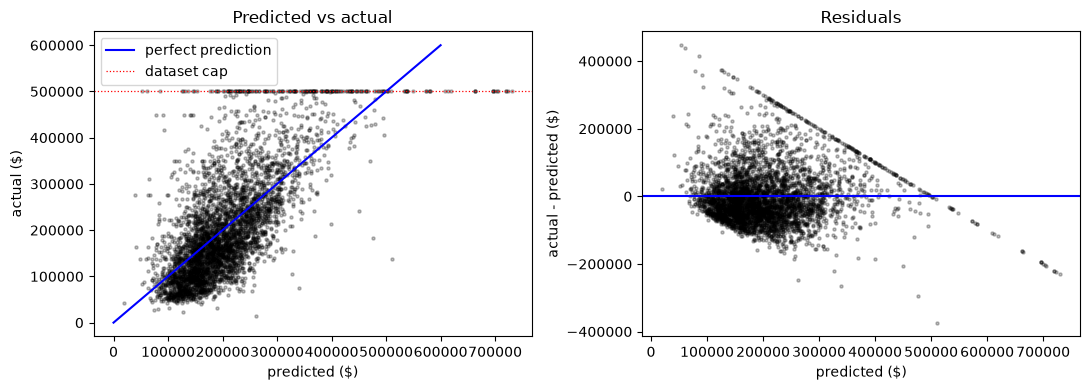

capped neighbourhoods (n=185): actual $500,001 vs predicted $372,899 on average
they are 4.5% of neighbourhoods but 12% of all the error
share of predictions within $50,000 of the truth: 52%
biggest over-prediction: $373,551   biggest under-prediction: $447,079


In [25]:
name2 = f'income + {second}'
pred = results[name2][1]
actual = y_test.to_numpy()
resid = actual - pred

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pred, actual, s=5, alpha=0.25, color='black')
ax[0].plot([0, 600_000], [0, 600_000], 'b-', lw=1.5, label='perfect prediction')
ax[0].axhline(CAP, color='r', ls=':', lw=0.9, label='dataset cap')
ax[0].set_xlabel('predicted ($)'); ax[0].set_ylabel('actual ($)'); ax[0].set_title('Predicted vs actual'); ax[0].legend()
ax[1].scatter(pred, resid, s=5, alpha=0.25, color='black')
ax[1].axhline(0, color='b', lw=1.5)
ax[1].set_xlabel('predicted ($)'); ax[1].set_ylabel('actual - predicted ($)'); ax[1].set_title('Residuals')
plt.tight_layout(); plt.show()

share_capped = np.abs(resid[capped_test]).sum() / np.abs(resid).sum()
print(f'capped neighbourhoods (n={capped_test.sum()}): actual ${actual[capped_test].mean():,.0f} vs predicted ${pred[capped_test].mean():,.0f} on average')
print(f'they are {capped_test.mean() * 100:.1f}% of neighbourhoods but {share_capped * 100:.0f}% of all the error')
print(f'share of predictions within $50,000 of the truth: {(np.abs(resid) <= 50_000).mean() * 100:.0f}%')
print(f'biggest over-prediction: ${-resid.min():,.0f}   biggest under-prediction: ${resid.max():,.0f}')

### What I found (first run; numbers are on held-out neighbourhoods)

| Model | R² | Typical error (MAE) |
|---|---|---|
| Income only | 0.447 | $63,500 |
| Income + HouseAge | 0.484 | $61,200 |
| Income + latitude + longitude | 0.567 | $55,300 |
| All 8 features | 0.594 | $53,500 |

- **Income alone explains about 45% of the variation in house values.** Every extra $10,000 of median income adds about $42,000 to the predicted value. The typical miss is about $63,500, roughly a third of the median value ($179,700).
- **The best second feature (HouseAge) barely helps**: +0.035 R² and about $2,400 off the error.
- **Location only helps as a pair.** Adding latitude *or* longitude on its own gains almost nothing (at most +0.007 R²), but income + latitude + longitude together jump to 0.567. Neither number means much alone; together they place the neighbourhood on the map. (Probably because California's expensive coast runs diagonally, but I haven't tested that.)
- **A straight line has a ceiling.** Using all eight features only reaches R² 0.594.
- **Where it is wrong:** the 4.5% of test neighbourhoods at the $500,000 cap are predicted at about $373,000 on average and cause 12% of all the error. The dataset can't show values above the cap, so part of that "error" is missing data. Only 52% of predictions land within $50,000 of the truth, and the models that use location predict a *negative* house value for 19 to 24 neighbourhoods.

### Recommendation
Use this model to **explain** ("income and location drive value; about $42,000 per $10,000 of income"), not to **price** individual homes: half of its predictions are off by more than $50,000. For accuracy, try a model that can bend to fit the map, such as the tree models in workshop 3-3 (I haven't tested whether it would do better here).

**Caveats:** 1990 census data and 1990 dollars; neighbourhood medians, not individual homes; values capped at $500,000; one random 80/20 split.